            Shooter Type  Shift  Extra PPG  Low (5%)  High (95%)
     Deep-range creators    0.0      0.215     0.202       0.229
  Volume above-the-break    0.0      0.041     0.037       0.046
Corner / catch-and-shoot    0.0      0.023     0.021       0.026
     Deep-range creators    0.1      0.238     0.211       0.266
  Volume above-the-break    0.1      0.050     0.039       0.062
Corner / catch-and-shoot    0.1      0.032     0.023       0.040
     Deep-range creators    0.2      0.261     0.225       0.297
  Volume above-the-break    0.2      0.059     0.044       0.075
Corner / catch-and-shoot    0.2      0.040     0.029       0.051
     Deep-range creators    0.3      0.285     0.241       0.329
  Volume above-the-break    0.3      0.068     0.049       0.087
Corner / catch-and-shoot    0.3      0.048     0.034       0.062


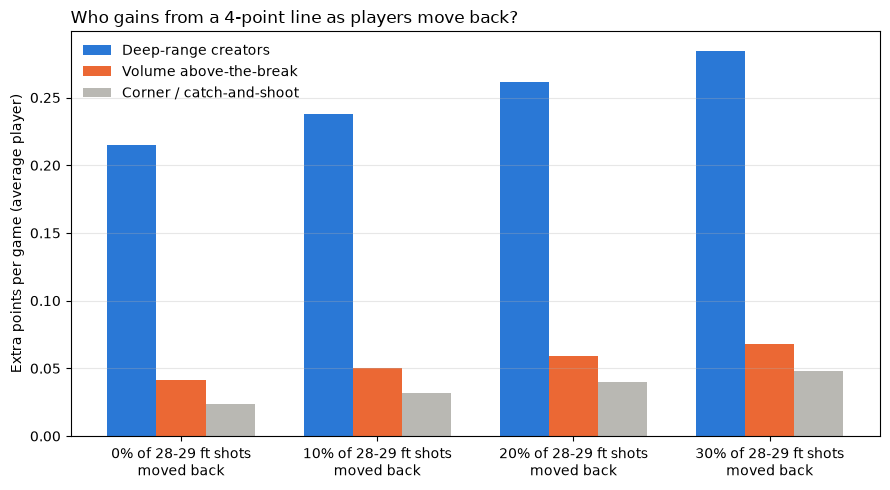

In [2]:
"""Monte Carlo simulation by shooter type.

Connects the two models:
  1. K-means (nba_four_point_kmeans.py) -> each player-season's shooter type
  2. Monte Carlo -> extra points per game under a 4-point line (30+ ft),
     with players moving some of their 28-29 ft threes back past the line

Question: once players change how they shoot, which shooter type gains the most?

Run nba_four_point_kmeans.py first (it creates kmeans_shooter_types.csv).
"""
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

N_SIMS = 10_000
SHIFTS = [0.0, 0.10, 0.20, 0.30]   # share of 28-29 ft threes moved back to 30+ ft
MIN_ATTEMPTS = 20                  # fewer attempts than this -> use the league rate
rng = np.random.default_rng(42)

# ---------- Data: one row per player-season, heaves removed ----------
df = pd.read_csv("dataset2_top50_3pm_summary.csv")
types = pd.read_csv("kmeans_shooter_types.csv")[["Season", "Player", "Shooter Type"]]
df = df.merge(types, on=["Season", "Player"])

deep_A = df["30+ ft 3PA"] - df["Heaves 3PA"]   # shots that would become 4s
deep_M = df["30+ ft 3PM"] - df["Heaves 3PM"]
near_A, near_M = df["28-29 ft 3PA"], df["28-29 ft 3PM"]   # shots that could move back


def rate(makes, attempts):
    """Player's make rate, or the league rate if they have too few attempts."""
    league = makes.sum() / attempts.sum()
    return np.where(attempts >= MIN_ATTEMPTS, makes / attempts.clip(lower=1), league)


p_deep = rate(deep_M, deep_A)   # make rate from 30+ ft (also used for moved shots)
p_near = rate(near_M, near_A)   # make rate from 28-29 ft

# ---------- Simulate: every player x every simulated season at once ----------
# Arrays have shape (players, N_SIMS): one column per simulated season
def simulate(shift):
    deep_att = rng.poisson(deep_A.to_numpy()[:, None], (len(df), N_SIMS))
    moved_att = rng.poisson(shift * near_A.to_numpy()[:, None], (len(df), N_SIMS))

    deep_makes = rng.binomial(deep_att, p_deep[:, None])      # +1 pt each (3 -> 4)
    moved_as_4 = rng.binomial(moved_att, p_deep[:, None])     # moved shot, worth 4
    moved_as_3 = rng.binomial(moved_att, p_near[:, None])     # same shot if not moved, worth 3

    extra_points = deep_makes + 4 * moved_as_4 - 3 * moved_as_3
    return extra_points / df["GP"].to_numpy()[:, None]       # extra PPG


# ---------- Average each shooter type in every simulated season ----------
rows = []
for shift in SHIFTS:
    sims = simulate(shift)
    for name in df["Shooter Type"].unique():
        in_type = (df["Shooter Type"] == name).to_numpy()
        type_avg = sims[in_type].mean(axis=0)   # one average per simulated season
        rows.append({"Shooter Type": name, "Shift": shift,
                     "Extra PPG": type_avg.mean(),
                     "Low (5%)": np.percentile(type_avg, 5),
                     "High (95%)": np.percentile(type_avg, 95)})
results = pd.DataFrame(rows)
results.to_csv("four_point_by_type.csv", index=False)
print(results.round(3).to_string(index=False))

# ---------- Chart: grouped bars (90% ranges are in four_point_by_type.csv) ----------
colors = {"Deep-range creators": "#2a78d6", "Volume above-the-break": "#eb6834",
          "Corner / catch-and-shoot": "#b9b8b3"}
fig, ax = plt.subplots(figsize=(9, 5))
width = 0.25
for i, (name, color) in enumerate(colors.items()):
    r = results[results["Shooter Type"] == name]
    x = np.arange(len(SHIFTS)) + (i - 1) * width
    ax.bar(x, r["Extra PPG"], width, color=color, label=name)
ax.set_xticks(range(len(SHIFTS)), [f"{s:.0%} of 28-29 ft shots\nmoved back" for s in SHIFTS])
ax.set_ylabel("Extra points per game (average player)")
ax.set_title("Who gains from a 4-point line as players move back?", loc="left")
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig("four_point_by_type.png", dpi=150)
plt.show()